<a href="https://colab.research.google.com/github/vinoimaya07-svg/ML-LAB/blob/main/163MiniProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving Customer Complaints Sentiment and Priority Dataset.csv to Customer Complaints Sentiment and Priority Dataset.csv
Uploaded files:
Customer Complaints Sentiment and Priority Dataset.csv


In [4]:
import os

print("Files in Colab:")
print(os.listdir())

Files in Colab:
['.config', 'Customer Complaints Sentiment and Priority Dataset.csv', 'sample_data']


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [10]:
file_name = "Customer Complaints Sentiment and Priority Dataset.csv"

df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1750, 4)


,Consumer_complaint,Product,Sentiment,Priority
0,I had overdraft protection with Regions Bank i...,Checking or savings account or service,0,1
1,"I am the sole, legal representative of my dece...",Checking or savings account or service,0,1
2,This bank has consistantly manipulated my dire...,Checking or savings account or service,0,0
3,I enrolled in a Citibank checking account in X...,Checking or savings account or service,0,1
4,TIAA-XXXX has not responded to multiple reque...,Checking or savings account or service,0,1


In [11]:
# Remove spaces from column names
df.columns = df.columns.str.strip()

# Clean text
df["Consumer_complaint"] = df["Consumer_complaint"].astype(str).str.strip()
df["Product"] = df["Product"].astype(str).str.strip()

# Convert labels to numbers
df["Sentiment"] = pd.to_numeric(df["Sentiment"], errors="coerce")
df["Priority"] = pd.to_numeric(df["Priority"], errors="coerce")

# Remove invalid rows
df = df.dropna(
    subset=["Consumer_complaint", "Product", "Sentiment", "Priority"]
)

df["Sentiment"] = df["Sentiment"].astype(int)
df["Priority"] = df["Priority"].astype(int)

print("Clean dataset shape:", df.shape)

Clean dataset shape: (1750, 4)


In [12]:
X = df["Consumer_complaint"]
y = df["Product"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1400
Testing samples: 350


In [13]:
category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),

    ("classifier", LogisticRegression(max_iter=1000))
])

category_model.fit(X_train, y_train)

category_pred = category_model.predict(X_test)

accuracy = accuracy_score(y_test, category_pred)

print("Category Prediction Accuracy:", round(accuracy * 100, 2), "%")

Category Prediction Accuracy: 79.14 %


In [14]:
print(classification_report(y_test, category_pred))

                                                    precision    recall  f1-score   support

            Checking or savings account or service       0.75      0.78      0.76        50
                       Credit card or prepaid card       0.78      0.76      0.77        50
                Credit reporting, repair, or other       0.80      0.82      0.81        50
                                   Debt collection       0.74      0.80      0.77        50
                                             Loans       0.74      0.74      0.74        50
Money transfer, virtual currency, or money service       0.83      0.80      0.82        50
                                          Mortgage       0.91      0.84      0.88        50

                                          accuracy                           0.79       350
                                         macro avg       0.79      0.79      0.79       350
                                      weighted avg       0.79      0.79      0

In [15]:
X = df["Consumer_complaint"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),

    ("classifier", LogisticRegression(max_iter=1000))
])

sentiment_model.fit(X_train, y_train)

sentiment_pred = sentiment_model.predict(X_test)

print(
    "Sentiment Prediction Accuracy:",
    round(accuracy_score(y_test, sentiment_pred) * 100, 2),
    "%"
)

Sentiment Prediction Accuracy: 74.0 %


In [16]:
print(classification_report(y_test, sentiment_pred))

              precision    recall  f1-score   support

           0       0.74      1.00      0.85       259
           1       0.50      0.01      0.02        91

    accuracy                           0.74       350
   macro avg       0.62      0.50      0.44       350
weighted avg       0.68      0.74      0.63       350



In [17]:
X = df["Consumer_complaint"]
y = df["Priority"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

priority_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),

    ("classifier", LogisticRegression(max_iter=1000))
])

priority_model.fit(X_train, y_train)

priority_pred = priority_model.predict(X_test)

print(
    "Priority Prediction Accuracy:",
    round(accuracy_score(y_test, priority_pred) * 100, 2),
    "%"
)

Priority Prediction Accuracy: 80.86 %


In [18]:
print(classification_report(y_test, priority_pred))

              precision    recall  f1-score   support

           0       0.90      0.12      0.21        75
           1       0.81      1.00      0.89       275

    accuracy                           0.81       350
   macro avg       0.85      0.56      0.55       350
weighted avg       0.83      0.81      0.75       350



In [19]:
department_mapping = {
    "Checking or savings account or service":
        "Banking / Account Services",

    "Credit card or prepaid card":
        "Credit Card Services",

    "Credit reporting, repair, or other":
        "Credit Reporting Department",

    "Debt collection":
        "Debt Collection Department",

    "Loans":
        "Loan Services",

    "Mortgage":
        "Mortgage Services",

    "Money transfer, virtual currency, or money service":
        "Money Transfer Services"
}

In [20]:
def analyze_complaint(complaint):

    # Predict category
    category = category_model.predict([complaint])[0]

    # Predict sentiment
    sentiment = sentiment_model.predict([complaint])[0]

    # Predict priority
    priority = priority_model.predict([complaint])[0]

    # Find department
    department = department_mapping.get(
        category,
        "General Customer Support"
    )

    # Category confidence
    probabilities = category_model.predict_proba([complaint])[0]
    confidence = max(probabilities) * 100

    print("=" * 60)
    print("       CONSUMER COMPLAINT ANALYZER")
    print("=" * 60)

    print("\nComplaint:")
    print(complaint)

    print("\nPredicted Product:")
    print(category)

    print("\nPredicted Sentiment:")
    print(sentiment)

    print("\nPredicted Priority:")
    print(priority)

    print("\nRecommended Department:")
    print(department)

    print("\nCategory Confidence:")
    print(round(confidence, 2), "%")

    print("=" * 60)

In [21]:
complaint = """
I was charged a fee on my bank account that I did not authorize.
I contacted the bank several times but the issue has still not
been resolved.
"""

analyze_complaint(complaint)

       CONSUMER COMPLAINT ANALYZER

Complaint:

I was charged a fee on my bank account that I did not authorize.
I contacted the bank several times but the issue has still not
been resolved.


Predicted Product:
Checking or savings account or service

Predicted Sentiment:
0

Predicted Priority:
1

Recommended Department:
Banking / Account Services

Category Confidence:
55.73 %


In [22]:
user_complaint = input("Enter your complaint: ")

analyze_complaint(user_complaint)

Enter your complaint: I have been receiving calls from a debt collector about a debt that does not belong to me.
       CONSUMER COMPLAINT ANALYZER

Complaint:
I have been receiving calls from a debt collector about a debt that does not belong to me.

Predicted Product:
Debt collection

Predicted Sentiment:
0

Predicted Priority:
1

Recommended Department:
Debt Collection Department

Category Confidence:
74.41 %


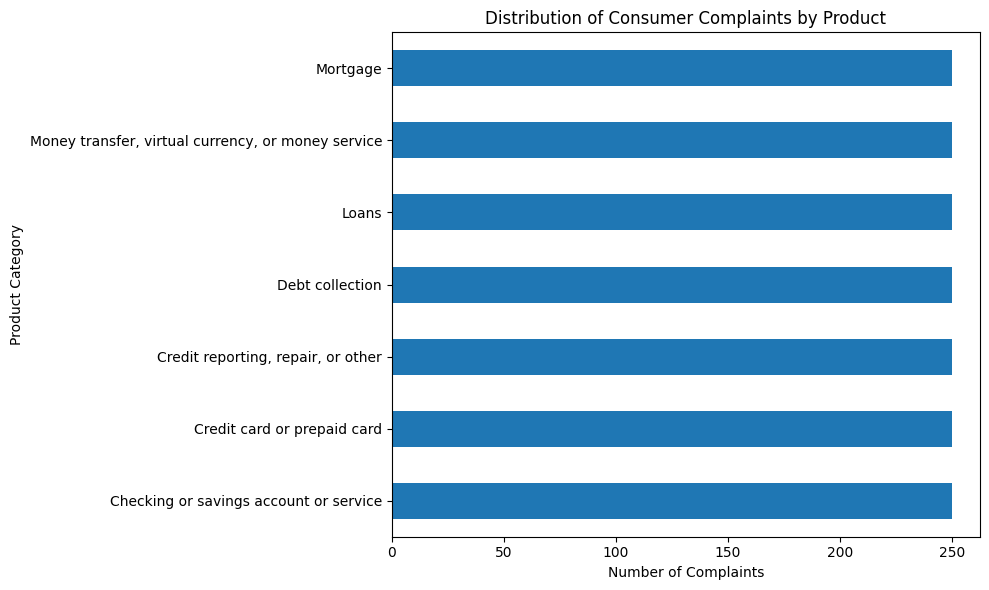

In [26]:
import matplotlib.pyplot as plt

product_counts = df["Product"].value_counts()

plt.figure(figsize=(10, 6))
product_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Consumer Complaints by Product")
plt.xlabel("Number of Complaints")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

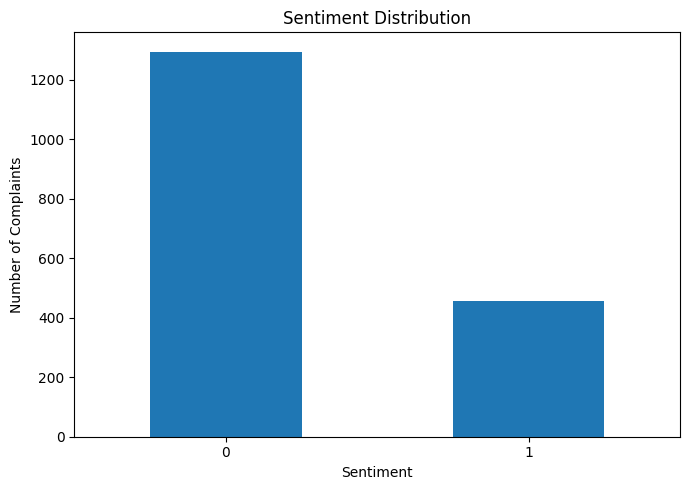

In [27]:
sentiment_counts = df["Sentiment"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

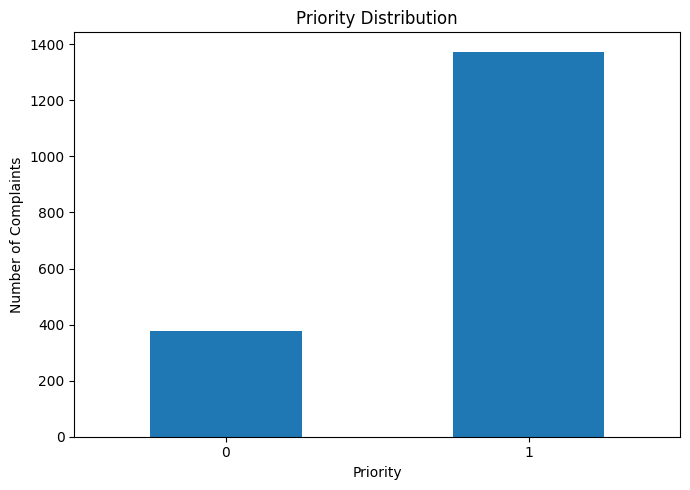

In [28]:
priority_counts = df["Priority"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
priority_counts.plot(kind="bar")

plt.title("Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()